In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc
import statsmodels.api as sm

In [ ]:
1. Сначала познакомимся с простой линейной моделью и задачей подгонки прямой под облако точек.
Для этого нужно сгенерировать модельные данные: массив X, где Xk = k/m для m = 10, 20, 50,
и массив Y, где Yi = aXi + b + εi, где a, b – количество гласных в ваших имени и фамилии

соответственно, случайные величины εi ∼ N (0, σ2) независимы (используйте σ = 1, σ = a/9).
(a) Найти оценки для коэффициентов прямой методом МНК (см. регрессия, OLS).
(b) Построить на одном графике облако точек, полученную прямую, исходную прямую.
(c) Сравнить полученные коэффициенты и оценку дисперсии ошибок с исходными.

10 a: 1.9585298757131313    b: 3.036614802946663    sigma: 0.3056258543623348


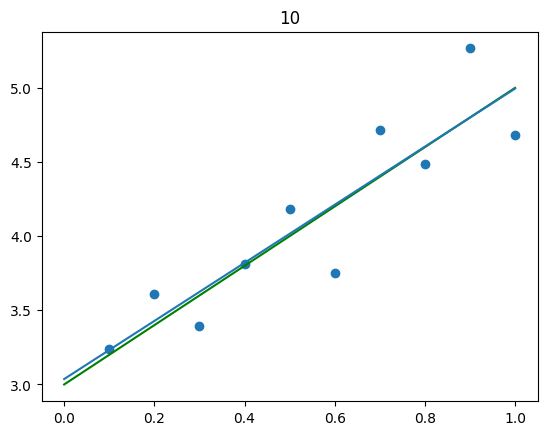

20 a: 2.2205541286053205    b: 2.834884773804592    sigma: 0.15024389965679738


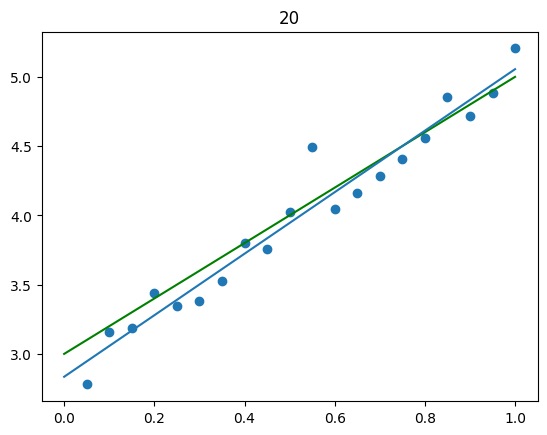

50 a: 2.04491238296245    b: 2.9983020602709978    sigma: 0.2594245675137938


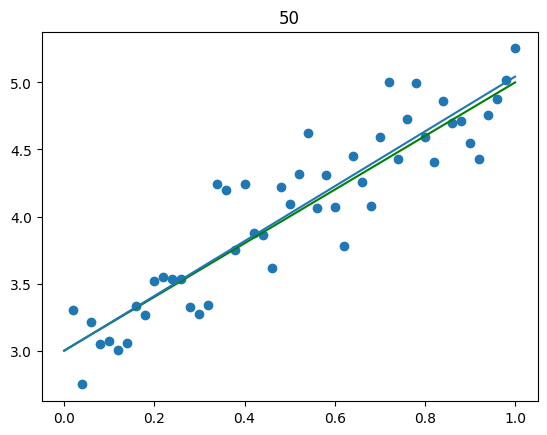

In [2]:
n = 100
a = 2
b = 3
sigma = 2/9
for m in [10,20,50]:
    x = [(k+1)/m for k in range(m)]
    eps = np.random.normal(0,sigma, size = m)
    y = [a*x[i] + b + eps[i] for i in range(m)]
    res = sm.OLS(y, sm.add_constant(x)).fit()
    a_est = res.params[1]
    b_est = res.params[0]
    print(m, "a:",res.params[1], "   b:", res.params[0], "   sigma:", np.sqrt(res.mse_resid) ) 
    
    l = np.linspace(0,1,100)
    line0 = [a*x + b for x in l]
    plt.plot(l, line0, color = "green")
    line1 = [a_est*x + b_est for x in l]
    plt.plot(l, line1)
    plt.scatter(x, y)
    plt.title(m)
    plt.show()

In [ ]:
2. Теперь посмотрим, как наши методы реагируют на сильно отклоняющиеся от прямой значения Y .
Для этого в массиве Y нужно изменить несколько элементов.
(a) Пусть Yt = aXt + b + 5σ для некоторого (одного!) t. Построить новую прямую методом МНК,
сравнить с прямой МНК, построенной в задаче 1. Рассмотреть случаи, когда Xt находится в
центре массива и когда Xt расположен на краю.
(b) Если Yt = aXt +b+5σ, а Ys = aXs +b−5σ, будут ли эти выбросы компенсировать друг друга?
Рассмотреть случаи, когда Xt, Xs находятся а) рядом б) на разных концах ряда.

10 a: 1.891051053839028    b: 3.1959035740996873    sigma: 0.47457155077588936


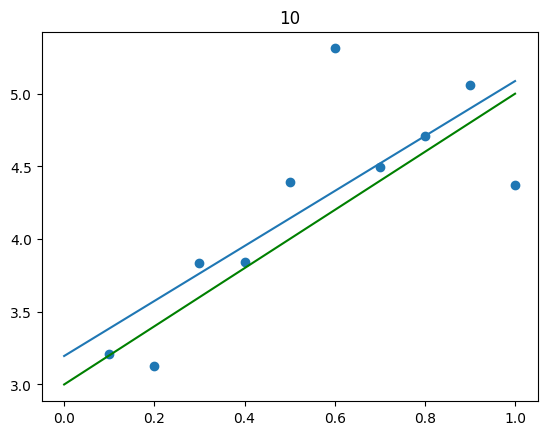

20 a: 1.939909596800025    b: 3.0775606187347204    sigma: 0.33603641559370445


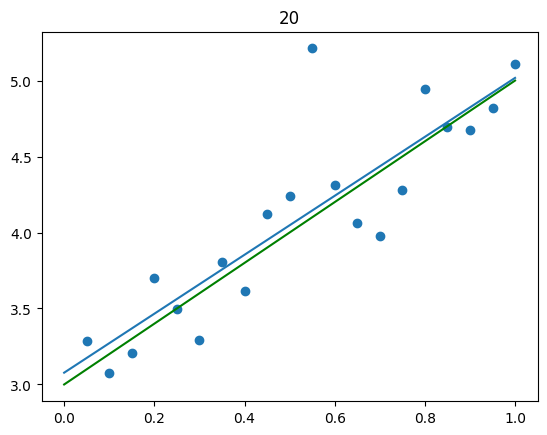

50 a: 1.9413448785369636    b: 3.0090155552348063    sigma: 0.27076732305896123


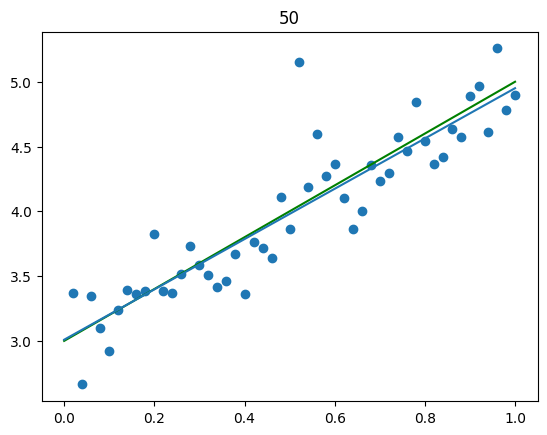

In [4]:
n = 100
a = 2
b = 3
t = 1
sigma = 2/9
for m in [10,20,50]:
    t = int(m/2)
    x = [(k+1)/m for k in range(m)]
    eps = np.random.normal(0,sigma, size = m)
    y = [a*x[i] + b + eps[i] for i in range(m)]
    y[t] = a*x[t] +b + 5*sigma
    res = sm.OLS(y, sm.add_constant(x)).fit()
    a_est = res.params[1]
    b_est = res.params[0]
    print(m, "a:",res.params[1], "   b:", res.params[0], "   sigma:", np.sqrt(res.mse_resid) ) 
    
    l = np.linspace(0,1,100)
    line0 = [a*x + b for x in l]
    plt.plot(l, line0, color = "green")
    line1 = [a_est*x + b_est for x in l]
    plt.plot(l, line1)
    plt.scatter(x, y)
    plt.title(m)
    plt.show()

10 a: -3.0365720307239483    b: 5.508414910214912    sigma: 2.0502961428647244


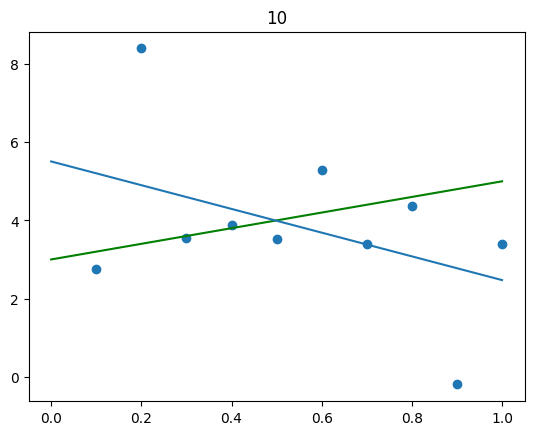

20 a: 0.04982293160850104    b: 4.130369193001931    sigma: 1.8446710556489556


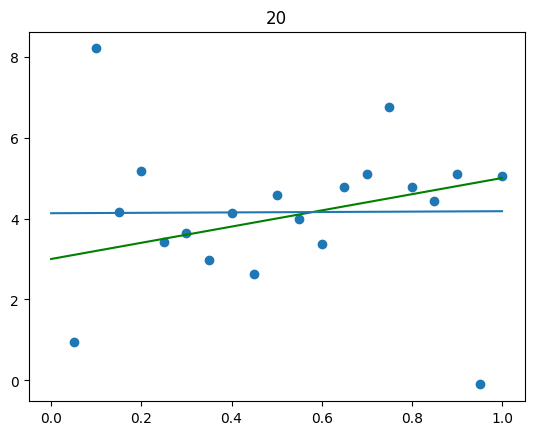

50 a: 1.1690000710809467    b: 3.6228347749052254    sigma: 1.4258106279730192


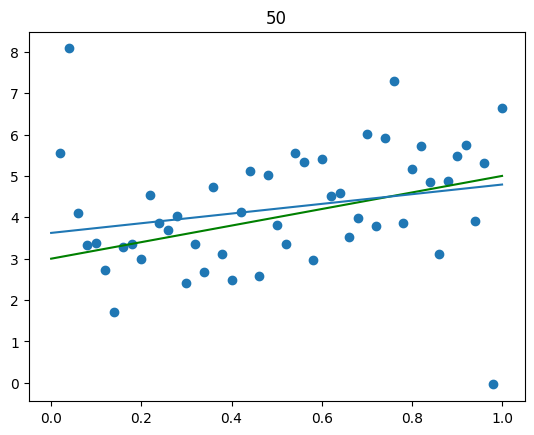

In [162]:
n = 100
a = 2
b = 3
t = 1
sigma = 1
for m in [10,20,50]:
    t = 1
    s = m-2
    x = [(k+1)/m for k in range(m)]
    eps = np.random.normal(0,sigma, size = m)
    y = [a*x[i] + b + eps[i] for i in range(m)]
    y[t] = a*x[t] +b + 5*sigma
    y[s] = a*x[s] +b - 5*sigma
    res = sm.OLS(y, sm.add_constant(x)).fit()
    a_est = res.params[1]
    b_est = res.params[0]
    print(m, "a:",res.params[1], "   b:", res.params[0], "   sigma:", np.sqrt(res.mse_resid) ) 
    
    l = np.linspace(0,1,100)
    line0 = [a*x + b for x in l]
    plt.plot(l, line0, color = "green")
    line1 = [a_est*x + b_est for x in l]
    plt.plot(l, line1)
    plt.scatter(x, y)
    plt.title(m)
    plt.show()

In [ ]:
3. Познакомимся с общей линейной моделью. Посмотрим, как метод МНК работает для подгонки
многочлена. Пусть X – тот же массив, Yi = a0 + a1Xi + · · · + akXk
i + εi
, εi ∼ N (0, σ2) независимы

(σ = 1).
(a) Построить МНК-оценки коэффициентов, считая что Y = a0 + a1X + · · · + adXd
i + ε, где

d = k, k + 1, k + 3, сравнить их с исходными.

(b) Построить на одном графике облако точек, полученный многочлен, исходный многочлен (от-
дельно для разных d).

(c) Построить прогноз в точках x = 1.2, 1.5, 2 для разных d, сравнить эти прогнозы.
(d) Сравнить графики многочленов, полученных в задаче при разных d, за пределами отрезка
[0, 1].


y = −2x^4 + 4x^3 − x − 2,

a:  [-2, -1, 0, 4, -2]
Степень 4: [ -1.78579398 -12.13163889  54.49697352 -83.97685502  43.8424938 ]


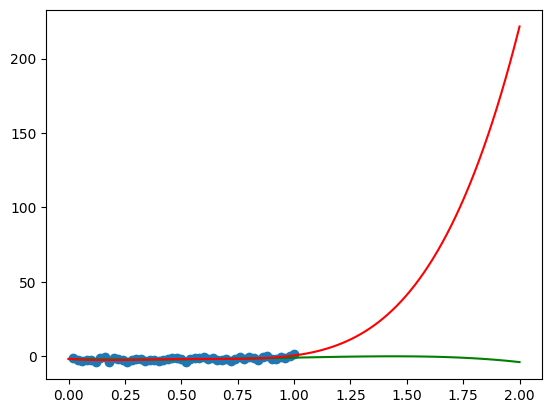

forecast [np.float64(7.931670887335287), np.float64(41.16567727307563), np.float64(221.6038829656)]
fact [-0.4352000000000009, -0.125, -4.0] 





Степень 5: [  -2.32475871    1.78805737  -37.28312251  152.31088527 -215.42331417
  101.67286587]


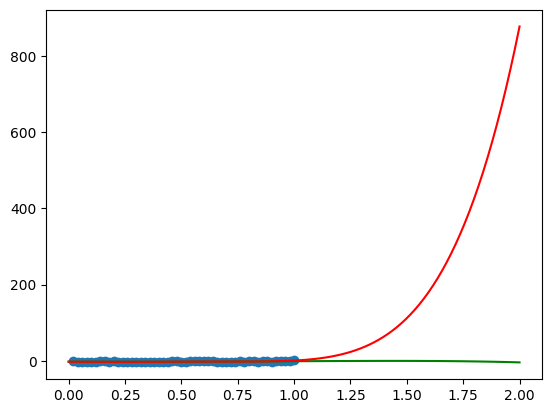

forecast [np.float64(15.61926480443617), np.float64(112.01733669698194), np.float64(877.3646292798799)]
fact [-0.4352000000000009, -0.125, -4.0] 





Степень 7: [-1.59091505e+00 -2.70199545e+01  2.80109948e+02 -1.36314032e+03
  3.46318878e+03 -4.65369401e+03  3.12022770e+03 -8.17331455e+02]


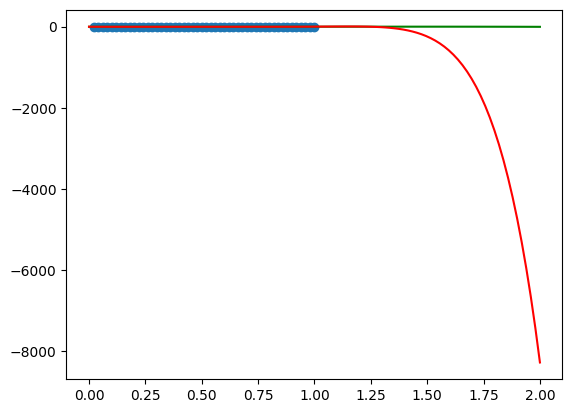

forecast [np.float64(3.528938779271357), np.float64(-242.59836373445614), np.float64(-8271.355399167733)]
fact [-0.4352000000000009, -0.125, -4.0] 







In [5]:
a = [-2,-1,0,4,-2]
m=50
x = np.arange(1, m+1) / m
y = -2 - x + 4*x**3 - 2*x**4 + np.random.normal(0, 1, m)
print("a: ", a)
for d in [4, 5, 7]:
    X = np.column_stack([x**i for i in range(d + 1)])
    a_est =  sm.OLS(y, X).fit().params
    print(f"Степень {d}:",a_est)

    l = np.linspace(0,2,100)
    line0 = [-2 - d + 4*d**3 - 2*d**4 for d in l]
    plt.plot(l, line0, color = "green")
    line1 = np.zeros_like(l)
    for i in range(d + 1):
        line1 += a_est[i] * (l ** i)
    plt.plot(l, line1, color = "red")
    plt.scatter(x, y)
    plt.show()

    x_forecast = [1.2, 1.5, 2.0]
    true_values = [-2 - xi + 4*xi**3 - 2*xi**4 for xi in x_forecast]

    forecasts = []
    for xi in x_forecast:
        forecast = sum(a_est[i] * (xi ** i) for i in range(d + 1))
        forecasts.append(forecast)
    print("forecast", forecasts)
    print("fact", true_values, "\n\n\n\n\n")